In [1]:
# ============ 셀 1: 설정 (E3: AdamW decay ρ 0.5·1.0 + AdamW full SAM → 2×3 격자 완성) ============
import os, json, time, math, random, glob, shutil, copy
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.nn.attention import sdpa_kernel, SDPBackend

assert torch.cuda.is_available(), "GPU가 꺼져 있어요. Settings → Accelerator → GPU T4 로 바꾸세요."
DEV = 'cuda'
OUT  = '/kaggle/working/exp_e3'
DATA = '/tmp/llm_data'
os.makedirs(OUT, exist_ok=True); os.makedirs(DATA, exist_ok=True)

CFG = dict(
    seed=0, ctx=256, vocab=50304, d_model=512, n_layer=6, n_head=8, grad_clip=1.0,
    muon_momentum=0.95, ns_steps=5,
    pre_epochs=10, pre_bs=32, pre_wd=0.1, warmup_frac=0.02, decay_frac=0.2,
    new_rhos=[0.5, 1.0],                # E2의 0.02~0.2에 이어서
    timing_steps=300,
    ft_lr_div=[10, 3], ft_steps=1000, ft_bs=32, ft_wd=0.1, ft_warmup=50, ft_seeds=[0, 1, 2], ft_eval_every=100,
    code_files=10000, code_max_chars=20000, eval_seqs=400, eval_bs=32,
    blimp_per_task=200, quant_bits=[8, 4], noise_gammas=[0.01, 0.02, 0.05], noise_reps=3,
    hutch_samples=20, lam_batches=3, hvp_iters=20, curv_batches=2, cka_seqs=64, cka_tokens=4096,
)
json.dump(CFG, open(f'{OUT}/config.json', 'w'), indent=2)

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def find_input(folder, name):
    hits = glob.glob(f'/kaggle/input/**/{folder}/{name}', recursive=True)
    assert hits, f"{folder}/{name}을 못 찾았어요. Add Input에서 해당 노트북을 추가했는지 확인하세요."
    return hits[0]

print('GPU :', torch.cuda.get_device_name(0), '| torch', torch.__version__)
for f in ['exp_llm_adamw/pre_shared.pt', 'exp_llm_adamw/pre_off.pt', 'exp_llm_adamw/pre_sam.pt', 'exp_llm_adamw/lr_sweep.json',
          'exp_e2/pretrain_metrics.json', 'exp_e2/ft_results.csv', 'exp_e2/ft_curves.json', 'exp_e2/ft_cka.json',
          'exp_e1/ft_curves.json', 'exp_e1/pretrain_metrics.json', 'exp_e1/ft_results_final.csv']:
    print('  입력 확인:', f, '→', '있음' if glob.glob(f'/kaggle/input/**/{f}', recursive=True) else '없음 ← Add Input 확인')

GPU : Tesla T4 | torch 2.11.0+cu128
  입력 확인: exp_llm_adamw/pre_shared.pt → 있음
  입력 확인: exp_llm_adamw/pre_off.pt → 있음
  입력 확인: exp_llm_adamw/pre_sam.pt → 있음
  입력 확인: exp_llm_adamw/lr_sweep.json → 있음
  입력 확인: exp_e2/pretrain_metrics.json → 있음
  입력 확인: exp_e2/ft_results.csv → 있음
  입력 확인: exp_e2/ft_curves.json → 있음
  입력 확인: exp_e2/ft_cka.json → 있음
  입력 확인: exp_e1/ft_curves.json → 있음
  입력 확인: exp_e1/pretrain_metrics.json → 있음
  입력 확인: exp_e1/ft_results_final.csv → 있음


In [2]:
# ============ 셀 2: BabyLM + 파이썬 코드 + BLiMP (E2와 동일) ============
from transformers import AutoTokenizer
from datasets import load_dataset
tok = AutoTokenizer.from_pretrained('gpt2'); tok.model_max_length = int(1e9)
EOS = tok.eos_token_id

def encode_texts(texts, bs=256):
    parts = []
    for i in range(0, len(texts), bs):
        for ids in tok(texts[i:i + bs])['input_ids']:
            parts.append(np.array(ids + [EOS], dtype=np.uint16))
    return np.concatenate(parts)

def chunk_lines(text, n=200):
    lines = text.split('\n')
    return ['\n'.join(lines[i:i + n]) for i in range(0, len(lines), n)]

if not os.path.exists(f'{DATA}/babylm_val.npy'):
    try:
        from huggingface_hub import snapshot_download
        root = snapshot_download('cambridge-climb/BabyLM', repo_type='dataset', allow_patterns=['10M/*', 'dev/*'])
        tr_files = sorted(f for f in glob.glob(f'{root}/10M/*') if os.path.isfile(f))
        dv_files = sorted(f for f in glob.glob(f'{root}/dev/*') if os.path.isfile(f))
        assert tr_files and dv_files, '파일 없음'
        tr_texts, dv_texts = [], []
        for f in tr_files: tr_texts += chunk_lines(open(f, encoding='utf-8', errors='ignore').read())
        for f in dv_files: dv_texts += chunk_lines(open(f, encoding='utf-8', errors='ignore').read()[:500_000])
    except Exception as e:
        print('2023판 다운로드 실패 → 2026판으로 대체:', repr(e)[:120])
        ds = load_dataset('BabyLM-community/BabyLM-2026-Strict-Small', split='train')
        col = [c for c, t in ds.features.items() if getattr(t, 'dtype', None) == 'string'][0]
        lines = [t for t in ds[col] if t and t.strip()]
        idx = np.random.RandomState(0).permutation(len(lines)); nv = len(lines) // 20
        dv_lines = [lines[i] for i in idx[:nv]]; tr_lines = [lines[i] for i in idx[nv:]]
        tr_texts = ['\n'.join(tr_lines[i:i + 200]) for i in range(0, len(tr_lines), 200)]
        dv_texts = ['\n'.join(dv_lines[i:i + 200]) for i in range(0, len(dv_lines), 200)]
    tr = encode_texts(tr_texts); dv = encode_texts(dv_texts)
    np.save(f'{DATA}/babylm_train.npy', tr); np.save(f'{DATA}/babylm_val.npy', dv)
    print(f'BabyLM 토큰: train {len(tr)/1e6:.1f}M, val {len(dv)/1e6:.1f}M   (기존: 15.7M / 0.8M)')

if not os.path.exists(f'{DATA}/code_val.npy'):
    try:
        ds = load_dataset('bigcode/the-stack-smol', data_dir='data/python', split='train')
    except Exception as e:
        print('the-stack-smol 실패 → codeparrot으로 대체:', repr(e)[:120])
        ds = load_dataset('codeparrot/codeparrot-clean-valid', split='train')
    n = min(CFG['code_files'], len(ds))
    ds = ds.shuffle(seed=0).select(range(n))
    files = [c[:CFG['code_max_chars']] for c in ds['content']]
    nv = n // 10
    cv = encode_texts(files[:nv]); ct = encode_texts(files[nv:])
    np.save(f'{DATA}/code_train.npy', ct); np.save(f'{DATA}/code_val.npy', cv)
    print(f'코드 토큰: train {len(ct)/1e6:.1f}M, val {len(cv)/1e6:.1f}M   (기존: 26.9M / 3.0M)')

if not os.path.exists(f'{DATA}/blimp.json'):
    from datasets import get_dataset_config_names
    for name in ['nyu-mll/blimp', 'blimp']:
        try:
            cfgs = get_dataset_config_names(name); break
        except Exception as e:
            print(f'{name} 설정 목록 실패:', repr(e)[:120])
    rng = np.random.RandomState(0); rows = []
    for c in cfgs:
        ds = load_dataset(name, c, split='train')
        for i in rng.choice(len(ds), min(CFG['blimp_per_task'], len(ds)), replace=False):
            r = ds[int(i)]
            rows.append(dict(task=c, field=r.get('field', 'unknown'), good=r['sentence_good'], bad=r['sentence_bad']))
    json.dump(rows, open(f'{DATA}/blimp.json', 'w'))
BLIMP = json.load(open(f'{DATA}/blimp.json'))
print(f'BLiMP: {len(BLIMP)}쌍, 현상 {len(set(r["task"] for r in BLIMP))}개')

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

Generating train split:   0%|          | 0/1000 [00:00<?, ? examples/s]

wh_vs_that_with_gap_long_distance/train-(…): reconstructing file:   0%|          |  0.00B / 84.1kB            

wh_vs_that_with_gap_long_distance/train-(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1000 [00:00<?, ? examples/s]

BLiMP: 13400쌍, 현상 67개


In [3]:
# ============ 셀 3: 모델, 파인튜닝, 평가 지표 함수 (E2와 동일 + full 학습용 초기화) ============
def load_tokens(name):
    return torch.from_numpy(np.load(f'{DATA}/{name}.npy').astype(np.int64)).to(DEV)

TR_BABY, VA_BABY = load_tokens('babylm_train'), load_tokens('babylm_val')
TR_CODE, VA_CODE = load_tokens('code_train'), load_tokens('code_val')

class Stream:
    def __init__(self, tokens, bs, ctx=CFG['ctx']):
        n = (len(tokens) - 1) // ctx
        self.chunks = tokens[:n * ctx + 1].unfold(0, ctx + 1, ctx)
        self.n, self.bs, self.spe = n, bs, n // bs
        self._key = None
    def batch(self, step, seed):
        ep, i = divmod(step, self.spe)
        if self._key != (seed, ep):
            g = torch.Generator().manual_seed(seed * 100003 + ep)
            self._perm = torch.randperm(self.n, generator=g).to(DEV); self._key = (seed, ep)
        b = self.chunks[self._perm[i * self.bs:(i + 1) * self.bs]]
        return b[:, :-1], b[:, 1:]

def make_eval(tokens, n, seed, ctx=CFG['ctx']):
    starts = np.random.RandomState(seed).randint(0, len(tokens) - ctx - 1, size=n)
    idx = torch.from_numpy(starts).to(DEV)[:, None] + torch.arange(ctx + 1, device=DEV)
    b = tokens[idx]
    return b[:, :-1], b[:, 1:]

EV_BABY = make_eval(VA_BABY, CFG['eval_seqs'], seed=11)
EV_CODE = make_eval(VA_CODE, CFG['eval_seqs'], seed=12)

class Block(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        self.h = h
        self.ln1 = nn.LayerNorm(d); self.qkv = nn.Linear(d, 3 * d); self.proj = nn.Linear(d, d)
        self.ln2 = nn.LayerNorm(d); self.fc = nn.Linear(d, 4 * d); self.fc2 = nn.Linear(4 * d, d)
    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(self.ln1(x)).split(C, dim=2)
        q, k, v = [t.view(B, T, self.h, C // self.h).transpose(1, 2) for t in (q, k, v)]
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        x = x + self.proj(y.transpose(1, 2).contiguous().view(B, T, C))
        return x + self.fc2(F.gelu(self.fc(self.ln2(x))))

class GPT(nn.Module):
    def __init__(self, V=CFG['vocab'], d=CFG['d_model'], L=CFG['n_layer'], h=CFG['n_head'], T=CFG['ctx']):
        super().__init__()
        self.wte = nn.Embedding(V, d); self.wpe = nn.Embedding(T, d)
        self.blocks = nn.ModuleList([Block(d, h) for _ in range(L)])
        self.lnf = nn.LayerNorm(d)
        for n, p in self.named_parameters():          # L1과 같은 초기화 (full SAM을 처음부터 학습할 때 필요)
            if p.ndim >= 2:
                std = 0.02 / math.sqrt(2 * L) if n.endswith(('proj.weight', 'fc2.weight')) else 0.02
                nn.init.normal_(p, 0.0, std)
            elif n.endswith('bias'):
                nn.init.zeros_(p)
    def forward(self, idx, targets=None, return_hidden=False):
        x = self.wte(idx) + self.wpe(torch.arange(idx.shape[1], device=idx.device))
        hs = [x] if return_hidden else None
        for b in self.blocks:
            x = b(x)
            if return_hidden: hs.append(x)
        logits = F.linear(self.lnf(x), self.wte.weight)
        if return_hidden: return logits, hs
        if targets is None: return logits
        return F.cross_entropy(logits.view(-1, logits.size(-1)), targets.reshape(-1))

def make_model():
    return GPT().to(DEV)

def load_model(sd):
    m = make_model(); m.load_state_dict(sd); return m

def cos_fn(total, warm):
    def f(s):
        if s < warm: return (s + 1) / warm
        return 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm)))
    return f

def train_step(model, opts, scaler, x, y):
    with torch.autocast('cuda', dtype=torch.float16):
        loss = model(x, y)
    model.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    for o in opts: scaler.unscale_(o)
    torch.nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip'])
    for o in opts: scaler.step(o)
    scaler.update()

@torch.no_grad()
def eval_loss(model, ev):
    model.eval(); X, Y = ev; tot = 0.0; bs = CFG['eval_bs']
    for i in range(0, len(X), bs):
        with torch.autocast('cuda', dtype=torch.float16):
            tot += model(X[i:i + bs], Y[i:i + bs]).float().item() * len(X[i:i + bs])
    model.train()
    return tot / len(X)

@torch.no_grad()
def token_acc(model, ev):
    model.eval(); X, Y = ev; hit = 0; n = 0; bs = CFG['eval_bs']
    for i in range(0, len(X), bs):
        with torch.autocast('cuda', dtype=torch.float16):
            pred = model(X[i:i + bs]).argmax(-1)
        hit += (pred == Y[i:i + bs]).sum().item(); n += Y[i:i + bs].numel()
    model.train()
    return hit / n

_ids = lambda s: [EOS] + tok(s)['input_ids']
BL_GOOD = [_ids(r['good']) for r in BLIMP]; BL_BAD = [_ids(r['bad']) for r in BLIMP]
BL_FIELD = np.array([r['field'] for r in BLIMP])

@torch.no_grad()
def sent_logprob(model, seqs, bs=128):
    model.eval(); out = np.zeros(len(seqs)); order = np.argsort([len(s) for s in seqs])
    for i in range(0, len(seqs), bs):
        idx = order[i:i + bs]; L = max(len(seqs[j]) for j in idx)
        X = torch.full((len(idx), L), EOS, dtype=torch.long, device=DEV); M = torch.zeros((len(idx), L), device=DEV)
        for r, j in enumerate(idx):
            X[r, :len(seqs[j])] = torch.tensor(seqs[j], device=DEV); M[r, :len(seqs[j])] = 1
        with torch.autocast('cuda', dtype=torch.float16):
            logits = model(X[:, :-1])
        lp = torch.log_softmax(logits.float(), -1).gather(-1, X[:, 1:, None]).squeeze(-1) * M[:, 1:]
        out[idx] = lp.sum(1).cpu().numpy()
    model.train()
    return out

def blimp(model):
    ok = sent_logprob(model, BL_GOOD) > sent_logprob(model, BL_BAD)
    return dict(acc=float(ok.mean()), **{f'acc_{f}': float(ok[BL_FIELD == f].mean()) for f in sorted(set(BL_FIELD))})

@torch.no_grad()
def quantized(model, bits):
    m = copy.deepcopy(model); qmax = 2 ** (bits - 1) - 1
    for p in m.parameters():
        if p.ndim == 2:
            s = p.abs().amax(dim=1, keepdim=True).clamp(min=1e-8) / qmax
            p.copy_((p / s).round().clamp(-qmax - 1, qmax) * s)
    return m

def quant_metrics(model, base_baby, base_code):
    out = {}
    for b in CFG['quant_bits']:
        q = quantized(model, b)
        out[f'int{b}_baby_inc'] = eval_loss(q, EV_BABY) - base_baby
        out[f'int{b}_code_inc'] = eval_loss(q, EV_CODE) - base_code
        del q
    torch.cuda.empty_cache()
    return out

@torch.no_grad()
def noise_metrics(model, base_baby):
    mats = [p for p in model.parameters() if p.ndim == 2]; out = {}
    for g in CFG['noise_gammas']:
        vals = []
        for r in range(CFG['noise_reps']):
            gen = torch.Generator(device=DEV).manual_seed(1000 + r)
            backup = [p.detach().clone() for p in mats]
            for p in mats:
                p.add_(torch.randn(p.shape, generator=gen, device=DEV) * g * p.norm() / math.sqrt(p.numel()))
            vals.append(eval_loss(model, EV_BABY) - base_baby)
            for p, b in zip(mats, backup): p.copy_(b)
        out[f'noise{g:g}_inc'] = float(np.mean(vals))
    return out

def lambda_max(model, batch, iters):
    model.eval(); x, y = batch; params = list(model.parameters())
    with sdpa_kernel(SDPBackend.MATH):
        loss = model(x, y)
        grads = torch.autograd.grad(loss, params, create_graph=True)
        v = [torch.randn_like(p) for p in params]
        nrm = torch.sqrt(sum((a * a).sum() for a in v)); v = [a / nrm for a in v]
        lam = 0.0
        for _ in range(iters):
            Hv = torch.autograd.grad(grads, params, grad_outputs=v, retain_graph=True)
            lam = sum((h * a).sum() for h, a in zip(Hv, v)).item()
            nrm = torch.sqrt(sum((h * h).sum() for h in Hv)); v = [h.detach() / nrm for h in Hv]
    del grads
    return lam

def hutchinson_trace(model, batches, n):
    model.eval(); params = list(model.parameters()); vals = []
    with sdpa_kernel(SDPBackend.MATH):
        for k in range(n):
            x, y = batches[k % len(batches)]
            loss = model(x, y)
            grads = torch.autograd.grad(loss, params, create_graph=True)
            v = [torch.randint_like(p, 2) * 2 - 1 for p in params]
            Hv = torch.autograd.grad(grads, params, grad_outputs=v)
            vals.append(sum((h * a).sum() for h, a in zip(Hv, v)).item())
            del grads, Hv
    return float(np.mean(vals)), float(np.std(vals) / math.sqrt(n))

@torch.no_grad()
def rank_metrics(model):
    er, sr = [], []
    for p in model.blocks.parameters():
        if p.ndim == 2:
            s = torch.linalg.svdvals(p.float()); q = s / s.sum()
            er.append((torch.exp(-(q * torch.log(q + 1e-12)).sum()) / len(s)).item())
            sr.append((s.pow(2).sum() / s[0] ** 2).item())
    return dict(erank_norm=float(np.mean(er)), stable_rank=float(np.mean(sr)))

def dir_curvature(sd_pre, sd_post, batches):
    m = load_model(sd_pre); m.eval(); names = [n for n, _ in m.named_parameters()]
    params = [p for _, p in m.named_parameters()]
    delta = [(sd_post[n].float() - p.detach().float()) for n, p in zip(names, params)]
    dn2 = sum((d * d).sum() for d in delta).item()
    mp = load_model(sd_post); mp.eval(); g1, q2, act = [], [], []
    with sdpa_kernel(SDPBackend.MATH):
        for x, y in batches:
            loss = m(x, y)
            grads = torch.autograd.grad(loss, params, create_graph=True)
            gd = sum((g * d).sum() for g, d in zip(grads, delta))
            Hd = torch.autograd.grad(gd, params)
            dHd = sum((h * d).sum() for h, d in zip(Hd, delta)).item()
            with torch.no_grad():
                act.append((mp(x, y) - loss).item())
            g1.append(gd.item()); q2.append(dHd)
            del grads, Hd
    del m, mp; torch.cuda.empty_cache()
    return dict(dir_curv=float(np.mean(q2)) / dn2, first_order=float(np.mean(g1)),
                second_order=0.5 * float(np.mean(q2)), quad_pred=float(np.mean(g1)) + 0.5 * float(np.mean(q2)),
                actual_inc=float(np.mean(act)))

CKA_X = EV_BABY[0][:CFG['cka_seqs']]
CKA_IDX = torch.from_numpy(np.random.RandomState(7).choice(CKA_X.numel(), CFG['cka_tokens'], replace=False)).to(DEV)

@torch.no_grad()
def layer_feats(model):
    model.eval(); outs = None
    for i in range(0, len(CKA_X), 16):
        with torch.autocast('cuda', dtype=torch.float16):
            _, hs = model(CKA_X[i:i + 16], return_hidden=True)
        hs = [h.float().reshape(-1, h.size(-1)) for h in hs]
        outs = hs if outs is None else [torch.cat([a, b]) for a, b in zip(outs, hs)]
    return [h[CKA_IDX].double() for h in outs]

def linear_cka(A, B):
    A = A - A.mean(0); B = B - B.mean(0)
    return ((A.T @ B).norm() ** 2 / ((A.T @ A).norm() * (B.T @ B).norm())).item()

def delta_rel(sd_a, sd_b):
    num = den = 0.0
    for k, v in sd_a.items():
        if not v.is_floating_point(): continue
        num += (sd_b[k].float() - v.float()).pow(2).sum().item(); den += v.float().pow(2).sum().item()
    return math.sqrt(num / den)

def baby_at(curve, target):
    for a, b in zip(curve, curve[1:]):
        if b['code'] <= target:
            t = 1.0 if a['code'] == b['code'] else min(max((a['code'] - target) / (a['code'] - b['code']), 0), 1)
            return a['baby'] + t * (b['baby'] - a['baby'])
    return float('nan')

tr_stream = Stream(TR_BABY, 32)
SHARP_BATCHES = [tuple(t[:16] for t in tr_stream.batch(s, seed=999)) for s in range(max(CFG['lam_batches'], 4))]
CURV_BATCHES = SHARP_BATCHES[:CFG['curv_batches']]
print('도구 준비 완료')

도구 준비 완료


In [4]:
# ============ 셀 4: AdamW + 유클리드 SAM 사전학습 도구 (L1·E2와 동일) ============
TOTAL = CFG['pre_epochs'] * tr_stream.spe
S_dec = int(TOTAL * (1 - CFG['decay_frac']))
EVAL_EVERY = max(1, TOTAL // 20)

def wsd_fn(total, warm, decay_start):
    def f(s):
        if s < warm: return (s + 1) / warm
        if s < decay_start: return 1.0
        return max(0.0, (total - s) / (total - decay_start))
    return f
lr_fn = wsd_fn(TOTAL, max(1, int(TOTAL * CFG['warmup_frac'])), S_dec)
BEST_LR = min(json.load(open(find_input('exp_llm_adamw', 'lr_sweep.json'))).values(), key=lambda r: r['val_loss'])['lr']

def make_adamw(model, lr, wd):
    decay = [p for p in model.parameters() if p.ndim >= 2]
    no_decay = [p for p in model.parameters() if p.ndim < 2]
    opt = torch.optim.AdamW([{'params': decay, 'weight_decay': wd}, {'params': no_decay, 'weight_decay': 0.0}],
                            lr=lr, betas=(0.9, 0.95), eps=1e-8)
    for g in opt.param_groups: g['base_lr'] = lr
    return opt

def sam_step(model, opt, scaler, x, y, rho):
    with torch.autocast('cuda', dtype=torch.float16):
        loss = model(x, y)
    opt.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    used = 0
    if rho > 0:
        params = [p for p in model.parameters() if p.grad is not None]
        gn = torch.norm(torch.stack([p.grad.norm(2) for p in params]), 2)
        if torch.isfinite(gn).item() and gn.item() > 0:
            with torch.no_grad():
                backup = [p.detach().clone() for p in params]
                k = rho / (gn + 1e-12)
                for p in params: p.add_(p.grad * k)
            opt.zero_grad(set_to_none=True)
            with torch.autocast('cuda', dtype=torch.float16):
                loss2 = model(x, y)
            scaler.scale(loss2).backward()
            with torch.no_grad():
                for p, b in zip(params, backup): p.copy_(b)
            used = 1
    scaler.unscale_(opt)
    torch.nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip'])
    scaler.step(opt); scaler.update()
    return loss.detach(), used

def pre_train(model, opt, scaler, s_from, s_to, rho, log, tag):
    model.train(); t0 = time.time(); acc = torch.zeros((), device=DEV); cnt = 0; used = 0
    for s in range(s_from, s_to):
        f = lr_fn(s)
        for g in opt.param_groups: g['lr'] = g['base_lr'] * f
        x, y = tr_stream.batch(s, CFG['seed'])
        l, u = sam_step(model, opt, scaler, x, y, rho)
        acc += l; cnt += 1; used += u
        if (s + 1) % EVAL_EVERY == 0 or s + 1 == s_to:
            vl = eval_loss(model, EV_BABY); tl = (acc / cnt).item(); dt = time.time() - t0
            log.append(dict(step=s + 1, train_loss=tl, val_loss=vl, sam_steps=used, sec=dt))
            print(f'[{tag}] step {s+1}/{TOTAL}  train {tl:.3f}  BabyLM val {vl:.4f}  SAM {used}/{cnt}  {dt/cnt:.3f}s/step', flush=True)
            acc.zero_(); cnt = 0; used = 0; t0 = time.time()

print(f'AdamW lr (L1 스윕 최적): {BEST_LR:g} | 전체 {TOTAL} step, 감쇠 시작 {S_dec} (기존: 19140 / 15312)')

AdamW lr (L1 스윕 최적): 0.001 | 전체 19140 step, 감쇠 시작 15312 (기존: 19140 / 15312)


In [5]:
# ============ 셀 5: step 시간 측정 → decay ρ 0.5 / 1.0 갈래 (L1 80% 체크포인트에서) ============
SHARED = torch.load(find_input('exp_llm_adamw', 'pre_shared.pt'), map_location=DEV)
assert SHARED['step'] == S_dec, f'L1 체크포인트 step {SHARED["step"]} ≠ {S_dec}'

def from_shared():
    m = load_model(SHARED['model']); o = make_adamw(m, BEST_LR, CFG['pre_wd']); o.load_state_dict(SHARED['opt'])
    sc = torch.amp.GradScaler('cuda'); sc.load_state_dict(SHARED['scaler'])
    return m, o, sc

time_path, log_path = f'{OUT}/timing.json', f'{OUT}/pretrain_log.json'
TIME = json.load(open(time_path)) if os.path.exists(time_path) else {}
LOG = json.load(open(log_path)) if os.path.exists(log_path) else {}

for key, rho in [('step_nosam', 0.0), ('step_sam', 0.05)]:
    if key in TIME: continue
    m, o, sc = from_shared(); n = CFG['timing_steps']
    for s in range(S_dec, S_dec + n):
        if s == S_dec + 20: torch.cuda.synchronize(); t0 = time.time()
        for g in o.param_groups: g['lr'] = g['base_lr'] * lr_fn(s)
        x, y = tr_stream.batch(s, CFG['seed']); sam_step(m, o, sc, x, y, rho)
    torch.cuda.synchronize(); TIME[key] = (time.time() - t0) / (n - 20)
    del m, o; torch.cuda.empty_cache()
json.dump(TIME, open(time_path, 'w'), indent=1)
RATIO = TIME['step_sam'] / TIME['step_nosam']
A_DEC_COST = (1 - CFG['decay_frac']) + CFG['decay_frac'] * RATIO
A_FULL_COST = RATIO
print(f'AdamW step: SAM 없음 {TIME["step_nosam"]:.3f}s, 유클리드 SAM {TIME["step_sam"]:.3f}s '
      f'→ decay 20% 비용 {A_DEC_COST:.2f}배, full 비용 {A_FULL_COST:.2f}배  (E2: 0.190 / 0.389 / 1.21배)')

for rho in CFG['new_rhos']:
    tag = f'A_dec{rho:g}'
    if os.path.exists(f'{OUT}/{tag}.pt'):
        print(tag, '이미 있음 → 건너뜀'); continue
    m, o, sc = from_shared(); LOG[tag] = []
    print(f'\n=== {tag}: step {S_dec+1}~{TOTAL}, 유클리드 SAM ρ {rho} ===')
    t0 = time.time()
    pre_train(m, o, sc, S_dec, TOTAL, rho, LOG[tag], tag)
    TIME[tag] = time.time() - t0
    torch.save(m.state_dict(), f'{OUT}/{tag}.pt')
    json.dump(TIME, open(time_path, 'w'), indent=1); json.dump(LOG, open(log_path, 'w'), indent=1)
    print(f'{tag}: 최종 BabyLM {LOG[tag][-1]["val_loss"]:.4f} | {TIME[tag]/60:.1f}분  (E2: off 3.2881, ρ0.2 3.2672)')
    del m, o; torch.cuda.empty_cache()

AdamW step: SAM 없음 0.182s, 유클리드 SAM 0.395s → decay 20% 비용 1.24배, full 비용 2.18배  (E2: 0.190 / 0.389 / 1.21배)

=== A_dec0.5: step 15313~19140, 유클리드 SAM ρ 0.5 ===
[A_dec0.5] step 16269/19140  train 3.153  BabyLM val 3.3712  SAM 957/957  0.405s/step
[A_dec0.5] step 17226/19140  train 3.157  BabyLM val 3.3153  SAM 957/957  0.406s/step
[A_dec0.5] step 18183/19140  train 2.959  BabyLM val 3.2895  SAM 957/957  0.407s/step
[A_dec0.5] step 19140/19140  train 2.947  BabyLM val 3.2528  SAM 957/957  0.407s/step
A_dec0.5: 최종 BabyLM 3.2528 | 25.9분  (E2: off 3.2881, ρ0.2 3.2672)

=== A_dec1: step 15313~19140, 유클리드 SAM ρ 1.0 ===
[A_dec1] step 16269/19140  train 3.201  BabyLM val 3.3732  SAM 957/957  0.406s/step
[A_dec1] step 17226/19140  train 3.181  BabyLM val 3.3119  SAM 957/957  0.405s/step
[A_dec1] step 18183/19140  train 3.007  BabyLM val 3.2799  SAM 957/957  0.406s/step
[A_dec1] step 19140/19140  train 2.993  BabyLM val 3.2466  SAM 957/957  0.407s/step
A_dec1: 최종 BabyLM 3.2466 | 25.9분  (E2: off 3

In [6]:
# ============ 셀 6: E2 결과 불러오기 + 새 모델 사전학습 직후 지표 + 파인튜닝 함수 ============
PRE = json.load(open(find_input('exp_e2', 'pretrain_metrics.json')))          # A_off ~ A_dec0.2 (E2)
pre_path = f'{OUT}/pretrain_metrics.json'
if os.path.exists(pre_path): PRE.update(json.load(open(pre_path)))
PRE_SD, PRE_FEATS, DIVERGED = {}, {}, set()

def pre_metrics(key, sd, cost):
    m = load_model(sd)
    if not math.isfinite(eval_loss(m, EV_BABY)):
        DIVERGED.add(key); print(f'※ {key} 발산 → 제외'); del m; return
    PRE_SD[key] = sd; PRE_FEATS[key] = layer_feats(m)
    if key in PRE and key in json.load(open(pre_path)) if os.path.exists(pre_path) else False:
        del m; return
    t0 = time.time(); r = dict(cost=cost)
    r['baby_loss'] = eval_loss(m, EV_BABY); r['code_loss'] = eval_loss(m, EV_CODE)
    r['baby_acc'] = token_acc(m, EV_BABY); r['code_acc'] = token_acc(m, EV_CODE)
    r.update({f'blimp_{a}': v for a, v in blimp(m).items()})
    r.update(quant_metrics(m, r['baby_loss'], r['code_loss']))
    r.update(noise_metrics(m, r['baby_loss']))
    r['hess_trace'], r['hess_trace_se'] = hutchinson_trace(m, SHARP_BATCHES, CFG['hutch_samples'])
    lams = [lambda_max(m, b, CFG['hvp_iters']) for b in SHARP_BATCHES[:CFG['lam_batches']]]
    r['lambda_max'], r['lambda_max_sd'] = float(np.mean(lams)), float(np.std(lams))
    r.update(rank_metrics(m))
    PRE[key] = r
    new = {k: v for k, v in PRE.items() if k.startswith(('A_dec0.5', 'A_dec1', 'A_full'))}
    json.dump(new, open(pre_path, 'w'), indent=2)
    print(f'{key:10s} BabyLM {r["baby_loss"]:.4f} | BLiMP {r["blimp_acc"]*100:.2f}% | INT4 +{r["int4_baby_inc"]:.4f} | '
          f'노이즈0.02 +{r["noise0.02_inc"]:.4f} | trace {r["hess_trace"]:.1f} | λmax {r["lambda_max"]:.1f}±{r["lambda_max_sd"]:.1f} | {time.time()-t0:.0f}s', flush=True)
    del m; torch.cuda.empty_cache()

for rho in CFG['new_rhos']:
    tag = f'A_dec{rho:g}'
    pre_metrics(tag, torch.load(f'{OUT}/{tag}.pt', map_location=DEV), A_DEC_COST)

# ----- 파인튜닝 (E2와 동일 설정): E2 결과에 이어 붙임 -----
FT_LRS = [BEST_LR / d for d in CFG['ft_lr_div']]
STRENGTH = {round(lr, 12): s for lr, s in zip(FT_LRS, ['weak', 'strong'])}
code_stream = Stream(TR_CODE, CFG['ft_bs'])
ft_lr_fn = cos_fn(CFG['ft_steps'], CFG['ft_warmup'])

res_path, curve_path, cka_path = f'{OUT}/ft_results.csv', f'{OUT}/ft_curves.json', f'{OUT}/ft_cka.json'
if os.path.exists(res_path):
    ROWS = pd.read_csv(res_path).to_dict('records')
    CURVES = json.load(open(curve_path)); CKA = json.load(open(cka_path))
else:
    ROWS = pd.read_csv(find_input('exp_e2', 'ft_results.csv')).to_dict('records')
    CURVES = json.load(open(find_input('exp_e2', 'ft_curves.json')))
    CKA = json.load(open(find_input('exp_e2', 'ft_cka.json')))
print(f'E2 파인튜닝 결과 {len(ROWS)}개 불러옴 (30개면 정상)')

def run_ft(keys):
    done = {(r['strength'], int(r['seed']), r['model']) for r in ROWS}
    keys = [k for k in keys if k not in DIVERGED]
    total = len(FT_LRS) * len(CFG['ft_seeds']) * len(keys); k = 0; t_all = time.time()
    for lr in FT_LRS:
        st = STRENGTH[round(lr, 12)]
        for s in CFG['ft_seeds']:
            for key in keys:
                k += 1
                if (st, s, key) in done: continue
                t0 = time.time(); seed_all(s)
                model = load_model(PRE_SD[key])
                opts = [make_adamw(model, lr, CFG['ft_wd'])]; scaler = torch.amp.GradScaler('cuda')
                curve = [dict(step=0, code=eval_loss(model, EV_CODE), baby=eval_loss(model, EV_BABY))]
                model.train()
                for stp in range(CFG['ft_steps']):
                    f = ft_lr_fn(stp)
                    for g in opts[0].param_groups: g['lr'] = g['base_lr'] * f
                    x, y = code_stream.batch(stp, s)
                    train_step(model, opts, scaler, x, y)
                    if (stp + 1) % CFG['ft_eval_every'] == 0:
                        curve.append(dict(step=stp + 1, code=eval_loss(model, EV_CODE), baby=eval_loss(model, EV_BABY)))
                sd_post = {n: v.detach().clone() for n, v in model.state_dict().items()}
                P = PRE[key]; c0, cN = curve[0], curve[-1]
                row = dict(strength=st, seed=s, model=key, cost=P['cost'],
                           code_after=cN['code'], baby_before=c0['baby'], baby_after=cN['baby'], forgetting=cN['baby'] - c0['baby'],
                           code_acc_after=token_acc(model, EV_CODE), baby_acc_after=token_acc(model, EV_BABY))
                row['baby_acc_drop'] = P['baby_acc'] - row['baby_acc_after']
                bl = blimp(model); row['blimp_after'] = bl['acc']; row['blimp_drop'] = P['blimp_acc'] - bl['acc']
                for f_ in sorted(set(BL_FIELD)): row[f'blimp_drop_{f_}'] = P[f'blimp_acc_{f_}'] - bl[f'acc_{f_}']
                q = quant_metrics(model, cN['baby'], cN['code'])
                row['ft_int4_baby_inc'], row['ft_int4_code_inc'] = q['int4_baby_inc'], q['int4_code_inc']
                row['delta_rel'] = delta_rel(PRE_SD[key], sd_post)
                row.update(dir_curvature(PRE_SD[key], sd_post, CURV_BATCHES))
                CKA[f'{st}|{s}|{key}'] = [linear_cka(a, b) for a, b in zip(PRE_FEATS[key], layer_feats(model))]
                row['cka_last'] = CKA[f'{st}|{s}|{key}'][-1]
                ROWS.append(row); CURVES[f'{st}|{s}|{key}'] = curve
                pd.DataFrame(ROWS).to_csv(res_path, index=False)
                json.dump(CURVES, open(curve_path, 'w')); json.dump(CKA, open(cka_path, 'w'))
                print(f'[{k:2d}/{total}] {st:6s} seed={s} {key:10s} | 코드 {cN["code"]:.3f} | 망각 +{row["forgetting"]:.4f} | '
                      f'BLiMP {P["blimp_acc"]*100:.1f}→{bl["acc"]*100:.1f}% | 예측 {row["quad_pred"]:.3f} vs 실제 {row["actual_inc"]:.3f} | '
                      f'CKA끝 {row["cka_last"]:.3f} | {time.time()-t0:.0f}s (누적 {(time.time()-t_all)/60:.0f}분)', flush=True)
                del model, opts, sd_post; torch.cuda.empty_cache()
    print('파인튜닝 완료')

A_dec0.5   BabyLM 3.2528 | BLiMP 67.40% | INT4 +0.2185 | 노이즈0.02 +0.0049 | trace 2168.9 | λmax 6.3±0.4 | 98s
A_dec1     BabyLM 3.2466 | BLiMP 68.13% | INT4 +0.1200 | 노이즈0.02 +0.0033 | trace 1263.7 | λmax 2.4±0.1 | 97s
E2 파인튜닝 결과 30개 불러옴 (30개면 정상)


In [7]:
# ============ 셀 7: 새 decay 모델 파인튜닝 → E2와 합쳐 AdamW 최적 ρ 선택 ============
run_ft([f'A_dec{r:g}' for r in CFG['new_rhos']])

DEC_KEYS = ['A_dec0.02', 'A_dec0.05', 'A_dec0.1', 'A_dec0.2'] + [f'A_dec{r:g}' for r in CFG['new_rhos'] if f'A_dec{r:g}' not in DIVERGED]

def matched(df, keys, base='A_off'):
    """AdamW 모델들끼리 공통 코드 loss 지점에서 망각 비교 (E2 셀 7과 같은 방식)"""
    out = {}
    for st in ['weak', 'strong']:
        tgt = max(min(p['code'] for p in CURVES[f'{st}|{s}|{k}']) for k in [base] + keys for s in CFG['ft_seeds'])
        mf = {k: np.array([baby_at(CURVES[f'{st}|{s}|{k}'], tgt) - CURVES[f'{st}|{s}|{k}'][0]['baby'] for s in CFG['ft_seeds']])
              for k in [base] + keys}
        code = {k: np.array([CURVES[f'{st}|{s}|{k}'][-1]['code'] for s in CFG['ft_seeds']]) for k in [base] + keys}
        for k in keys:
            out.setdefault(k, {})[st] = dict(target=tgt, mf=mf[k].mean(), red=1 - mf[k].mean() / mf[base].mean(),
                                             wins=int((mf[base] - mf[k] > 0).sum()), dcode=(code[base] - code[k]).mean())
    return out

df = pd.DataFrame(ROWS)
M = matched(df, DEC_KEYS)
print('===== AdamW decay ρ 전체 (A_off 대비, AdamW끼리 공통 지점) =====')
for k in DEC_KEYS:
    w, s_ = M[k]['weak'], M[k]['strong']
    print(f'  {k:10s} 사전 loss {PRE[k]["baby_loss"]:.4f} | BLiMP {PRE[k]["blimp_acc"]*100:.2f}% | INT4 +{PRE[k]["int4_baby_inc"]:.3f} | '
          f'망각 감소 약 {w["red"]*100:+5.1f}% ({w["wins"]}/3), 강 {s_["red"]*100:+5.1f}% ({s_["wins"]}/3) | '
          f'코드 loss 차 약 {w["dcode"]:+.4f}, 강 {s_["dcode"]:+.4f}')

ok = [k for k in DEC_KEYS if PRE[k]['baby_loss'] <= PRE['A_off']['baby_loss'] + 0.003
      and min(M[k]['weak']['dcode'], M[k]['strong']['dcode']) >= -0.02]
BEST_DEC = max(ok, key=lambda k: M[k]['weak']['red'] + M[k]['strong']['red']) if ok else 'A_dec0.2'
FULL_RHO = float(BEST_DEC.replace('A_dec', ''))
print(f'\n→ AdamW decay 최적 ρ: {BEST_DEC}  (기준: 사전학습 손해 없음 + 코드 학습 손해 0.02 이내 + 망각 감소 최대)')
print(f'→ full SAM도 같은 ρ {FULL_RHO:g}로 학습 (Muon도 decay·full 같은 ρ 0.05)')
json.dump(dict(best_decay=BEST_DEC, full_rho=FULL_RHO), open(f'{OUT}/best_rho.json', 'w'))

[ 1/12] weak   seed=0 A_dec0.5   | 코드 2.819 | 망각 +0.5839 | BLiMP 67.4→64.9% | 예측 0.291 vs 실제 0.698 | CKA끝 0.882 | 241s (누적 4분)
[ 2/12] weak   seed=0 A_dec1     | 코드 2.831 | 망각 +0.4788 | BLiMP 68.1→65.3% | 예측 0.203 vs 실제 0.558 | CKA끝 0.906 | 241s (누적 8분)
[ 3/12] weak   seed=1 A_dec0.5   | 코드 2.821 | 망각 +0.5979 | BLiMP 67.4→64.6% | 예측 0.291 vs 실제 0.715 | CKA끝 0.871 | 241s (누적 12분)
[ 4/12] weak   seed=1 A_dec1     | 코드 2.828 | 망각 +0.4940 | BLiMP 68.1→65.3% | 예측 0.204 vs 실제 0.576 | CKA끝 0.895 | 241s (누적 16분)
[ 5/12] weak   seed=2 A_dec0.5   | 코드 2.824 | 망각 +0.5843 | BLiMP 67.4→65.1% | 예측 0.293 vs 실제 0.700 | CKA끝 0.860 | 241s (누적 20분)
[ 6/12] weak   seed=2 A_dec1     | 코드 2.833 | 망각 +0.4807 | BLiMP 68.1→65.1% | 예측 0.204 vs 실제 0.561 | CKA끝 0.886 | 240s (누적 24분)
[ 7/12] strong seed=0 A_dec0.5   | 코드 2.383 | 망각 +1.4005 | BLiMP 67.4→61.7% | 예측 0.947 vs 실제 1.624 | CKA끝 0.536 | 240s (누적 28분)
[ 8/12] strong seed=0 A_dec1     | 코드 2.389 | 망각 +1.2814 | BLiMP 68.1→62.5% | 예측 0.644 vs 실제 1.452 | CKA끝 

In [8]:
# ============ 셀 8: AdamW full 유클리드 SAM — L1과 같은 초기값·배치 순서로 처음부터 ============
FULL_KEY = f'A_full{FULL_RHO:g}'
full_path = f'{OUT}/{FULL_KEY}.pt'
if os.path.exists(full_path):
    print(FULL_KEY, '이미 있음 → 건너뜀')
else:
    seed_all(CFG['seed'])
    m = make_model(); o = make_adamw(m, BEST_LR, CFG['pre_wd']); sc = torch.amp.GradScaler('cuda')
    # L1 공통 구간과 같은 초기값인지 확인: 첫 평가 전 초기 loss 비교용
    LOG[FULL_KEY] = []
    print(f'=== {FULL_KEY}: step 1~{TOTAL}, 유클리드 SAM ρ {FULL_RHO:g} (예상 약 {TOTAL*TIME["step_sam"]/60:.0f}분) ===')
    t0 = time.time()
    pre_train(m, o, sc, 0, TOTAL, FULL_RHO, LOG[FULL_KEY], FULL_KEY)
    TIME[FULL_KEY] = time.time() - t0
    torch.save(m.state_dict(), full_path)
    json.dump(TIME, open(time_path, 'w'), indent=1); json.dump(LOG, open(log_path, 'w'), indent=1)
    print(f'{FULL_KEY}: 최종 BabyLM {LOG[FULL_KEY][-1]["val_loss"]:.4f} | {TIME[FULL_KEY]/60:.1f}분  (A_off 3.2881, {BEST_DEC} {PRE[BEST_DEC]["baby_loss"]:.4f})')
    del m, o; torch.cuda.empty_cache()

pre_metrics(FULL_KEY, torch.load(full_path, map_location=DEV), A_FULL_COST)
run_ft([FULL_KEY])

=== A_full1: step 1~19140, 유클리드 SAM ρ 1 (예상 약 126분) ===
[A_full1] step 957/19140  train 5.879  BabyLM val 4.6682  SAM 955/957  0.405s/step
[A_full1] step 1914/19140  train 4.468  BabyLM val 4.3076  SAM 957/957  0.404s/step
[A_full1] step 2871/19140  train 4.175  BabyLM val 4.0835  SAM 957/957  0.404s/step
[A_full1] step 3828/19140  train 3.988  BabyLM val 3.9238  SAM 957/957  0.404s/step
[A_full1] step 4785/19140  train 3.828  BabyLM val 3.8153  SAM 957/957  0.405s/step
[A_full1] step 5742/19140  train 3.756  BabyLM val 3.7374  SAM 957/957  0.407s/step
[A_full1] step 6699/19140  train 3.653  BabyLM val 3.6720  SAM 957/957  0.407s/step
[A_full1] step 7656/19140  train 3.616  BabyLM val 3.6277  SAM 957/957  0.407s/step
[A_full1] step 8613/19140  train 3.534  BabyLM val 3.5966  SAM 957/957  0.407s/step
[A_full1] step 9570/19140  train 3.532  BabyLM val 3.5604  SAM 957/957  0.407s/step
[A_full1] step 10527/19140  train 3.454  BabyLM val 3.5334  SAM 957/957  0.408s/step
[A_full1] step 11484

===== 1. AdamW 안에서 (A_off 대비, AdamW끼리 공통 지점) =====
  A_dec1     비용 1.24배 | 사전 loss 3.2466 | 망각 감소 약 +50.4% (3/3), 강 +42.5% (3/3) | 코드 loss 차 약 -0.0131, 강 -0.0120
  A_full1    비용 2.18배 | 사전 loss 3.3369 | 망각 감소 약 +0.6% (2/3), 강 +15.9% (3/3) | 코드 loss 차 약 -0.3577, 강 -0.3543
  [weak] decay가 full 망각 보호의 9077%를 얻음 (추가 비용: decay 0.24배, full 1.18배)
  [strong] decay가 full 망각 보호의 267%를 얻음 (추가 비용: decay 0.24배, full 1.18배)

===== 2. 2×3 격자 [weak] — 공통 코드 loss 3.321에서의 망각 =====
SAM        decay (1)  decay (ρ0.05)  full (1)  full (ρ0.05)      없음
optimizer                                                          
AdamW         0.3152            NaN    0.5691           NaN  0.6432
Muon             NaN         0.6262       NaN        0.6177  0.8617

  (자기 off 대비 감소율)
SAM        decay (1)  decay (ρ0.05)  full (1)  full (ρ0.05)   없음
optimizer                                                       
AdamW           51.0            NaN      11.5           NaN  0.0
Muon             NaN           27.3       Na

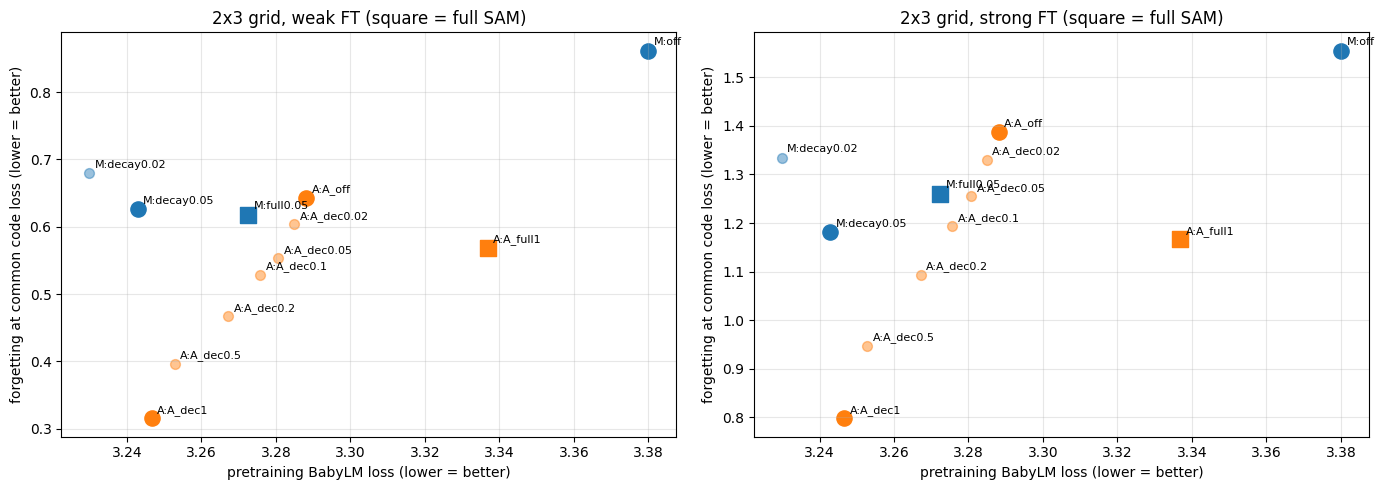

저장: /kaggle/working/exp_e3


In [9]:
# ============ 셀 9: 최종 결과 — AdamW decay vs full, 2×3 격자 (AdamW·Muon 공통 지점) ============
import matplotlib.pyplot as plt
df = pd.DataFrame(ROWS); df.to_csv(f'{OUT}/ft_results_final.csv', index=False)
A_ALL = ['A_off'] + DEC_KEYS + ([FULL_KEY] if FULL_KEY not in DIVERGED else [])

# 1) AdamW 안에서: decay 최적 vs full
MA = matched(df, A_ALL[1:])
print('===== 1. AdamW 안에서 (A_off 대비, AdamW끼리 공통 지점) =====')
for k in [BEST_DEC, FULL_KEY]:
    if k not in MA: continue
    w, s_ = MA[k]['weak'], MA[k]['strong']
    print(f'  {k:10s} 비용 {PRE[k]["cost"]:.2f}배 | 사전 loss {PRE[k]["baby_loss"]:.4f} | 망각 감소 약 {w["red"]*100:+.1f}% ({w["wins"]}/3), '
          f'강 {s_["red"]*100:+.1f}% ({s_["wins"]}/3) | 코드 loss 차 약 {w["dcode"]:+.4f}, 강 {s_["dcode"]:+.4f}')
if FULL_KEY in MA:
    for st in ['weak', 'strong']:
        r = MA[BEST_DEC][st]['red'] / MA[FULL_KEY][st]['red'] if MA[FULL_KEY][st]['red'] > 0 else float('nan')
        print(f'  [{st}] decay가 full 망각 보호의 {r*100:.0f}%를 얻음 (추가 비용: decay {PRE[BEST_DEC]["cost"]-1:.2f}배, full {PRE[FULL_KEY]["cost"]-1:.2f}배)')

# 2) 2×3 격자: AdamW + Muon 공통 코드 loss 지점
C_M = json.load(open(find_input('exp_e1', 'ft_curves.json')))
P_M = json.load(open(find_input('exp_e1', 'pretrain_metrics.json')))
D_M = pd.read_csv(find_input('exp_e1', 'ft_results_final.csv'))
M_COST = {'off': 1.00, 'decay0.02': 1.26, 'decay0.05': 1.26, 'full0.05': 2.27}
GRID = [('AdamW', '없음', 'A_off', CURVES, PRE, df, 'A_off'),
        ('AdamW', f'decay ({BEST_DEC[5:]})', BEST_DEC, CURVES, PRE, df, 'A_off'),
        ('AdamW', f'full ({FULL_KEY[6:]})', FULL_KEY, CURVES, PRE, df, 'A_off'),
        ('Muon', '없음', 'off', C_M, P_M, D_M, 'off'),
        ('Muon', 'decay (ρ0.05)', 'decay0.05', C_M, P_M, D_M, 'off'),
        ('Muon', 'full (ρ0.05)', 'full0.05', C_M, P_M, D_M, 'off')]
GRID = [g for g in GRID if g[2] not in DIVERGED]
EXTRA = [('AdamW', k, k, CURVES, PRE, df, 'A_off') for k in A_ALL if k not in {g[2] for g in GRID}] + \
        [('Muon', 'decay (ρ0.02)', 'decay0.02', C_M, P_M, D_M, 'off')]

out = []
for st in ['weak', 'strong']:
    allm = GRID + EXTRA
    tgt = max(min(p['code'] for p in C[f'{st}|{s}|{k}']) for _, _, k, C, *_ in allm for s in CFG['ft_seeds'])
    mf = {k: np.array([baby_at(C[f'{st}|{s}|{k}'], tgt) - C[f'{st}|{s}|{k}'][0]['baby'] for s in CFG['ft_seeds']])
          for _, _, k, C, *_ in allm}
    for opt_name, col, k, C, P, D, base in allm:
        sub = D[(D.strength == st) & (D.model == k)]
        cost = P[k]['cost'] if opt_name == 'AdamW' else M_COST[k]
        out.append(dict(strength=st, grid=(opt_name, col) in [(g[0], g[1]) for g in GRID], optimizer=opt_name, SAM=col, model=k,
                        cost=cost, pre_loss=P[k]['baby_loss'], pre_blimp=P[k]['blimp_acc'], pre_int4=P[k]['int4_baby_inc'],
                        hess_trace=P[k]['hess_trace'], code_after=np.mean([C[f'{st}|{s}|{k}'][-1]['code'] for s in CFG['ft_seeds']]),
                        matched_forgetting=mf[k].mean(), reduction_vs_own_off=1 - mf[k].mean() / mf[base].mean(),
                        blimp_after=sub.blimp_after.mean(), ft_int4=sub.ft_int4_baby_inc.mean(), cka_last=sub.cka_last.mean(), target=tgt))
comb = pd.DataFrame(out); comb.to_csv(f'{OUT}/grid_2x3.csv', index=False)

for st in ['weak', 'strong']:
    c = comb[(comb.strength == st) & comb.grid]
    print(f'\n===== 2. 2×3 격자 [{st}] — 공통 코드 loss {c.target.iloc[0]:.3f}에서의 망각 =====')
    print(c.pivot(index='optimizer', columns='SAM', values='matched_forgetting').round(4).to_string())
    print('\n  (자기 off 대비 감소율)')
    print((c.pivot(index='optimizer', columns='SAM', values='reduction_vs_own_off') * 100).round(1).to_string())
    for r in c.itertuples():
        print(f'  {r.optimizer:5s} {r.SAM:14s} 비용 {r.cost:.2f} | 사전 loss {r.pre_loss:.4f} | BLiMP {r.pre_blimp*100:.1f}→{r.blimp_after*100:.1f}% | '
              f'코드 후 {r.code_after:.3f} | 망각 {r.matched_forgetting:.4f} ({r.reduction_vs_own_off*100:+.1f}%) | '
              f'INT4 사전 +{r.pre_int4:.3f} / 후 +{r.ft_int4:.3f} | CKA끝 {r.cka_last:.3f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, st in zip(axes, ['weak', 'strong']):
    c = comb[comb.strength == st]
    for r in c.itertuples():
        ax.scatter(r.pre_loss, r.matched_forgetting, s=50 + 70 * r.grid, alpha=1 if r.grid else 0.45,
                   color='tab:orange' if r.optimizer == 'AdamW' else 'tab:blue', marker='s' if 'full' in r.model else 'o')
        ax.annotate(f'{r.optimizer[0]}:{r.model}', (r.pre_loss, r.matched_forgetting), textcoords='offset points', xytext=(4, 4), fontsize=8)
    ax.set_xlabel('pretraining BabyLM loss (lower = better)'); ax.set_ylabel('forgetting at common code loss (lower = better)')
    ax.set_title(f'2x3 grid, {st} FT (square = full SAM)'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{OUT}/grid_2x3.png', dpi=150); plt.show()
print('저장:', OUT)